# WIE 3007 Group Project: Component 1
## Dataset Simulation & Feature Engineering (AI-enhanced)

**Business case:** a Malaysian retail bank wants to anticipate which customers will **default** on a credit product, using structured account data *plus* unstructured customer text (feedback and call-centre notes).

**What this notebook does**

| Step | Brief requirement | Where |
|---|---|---|
| 1 | Simulate ≥ 1,000 financial/business records | §1 (1,500 customers, 29 raw columns) |
| 2 | GenAI-created realistic numerical **and** textual patterns | §1 |
| 3 | LLM/SLM feature extraction: sentiment, risk category, topic, customer segmentation | §2-§4 |
| 4 | Show the new features are useful | §3, §5 |

**Target for later modelling components:** `default_flag` (1 = defaulted / 90+ days past due). Classification task, about 13% positive (imbalanced, as in real credit data).

In [1]:
import sys, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from generate_dataset import generate
from extract_features import extract_offline, segment_customers, SEG_FEATURES
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 140)
sns.set_theme(style="whitegrid")
USE_HF = False   # True -> real Hugging Face SLMs (needs internet + `pip install transformers torch`)

## 1. Dataset simulation

The generator (`src/generate_dataset.py`) works in three layers so the data is realistic *and* free of target leakage:

1. **Numerical layer:** correlated demographics, income (Malaysian regions/employment), CTOS-style credit score, loan exposure, interest rate, DTI, utilisation, late payments, savings, channel behaviour.
2. **Latent layer:** a hidden *financial stress* score drives `default_flag`. A hidden *life-event shock* (job loss, illness…) also raises default risk but appears **only in the text**, so text features add real information beyond the numeric columns.
3. **Text layer:** `customer_feedback` and `agent_note` are generated from the latent text-stress, **not from the default flag**. Phrase pools were authored with GenAI and composed by a grammar, with Manglish code-mixing, typos, casing noise and missing notes.

Data-quality issues are injected on purpose (missing values, extreme outliers) so the cleaning/EDA step is meaningful.

In [2]:
raw, truth = generate(n=1500, seed=42)
raw.to_csv("data/bank_customers_raw.csv", index=False)
truth.to_csv("data/ground_truth_text_labels.csv", index=False)   # hidden labels, used ONLY to validate the extractors
print("Shape:", raw.shape, "| default rate:", round(raw["default_flag"].mean(), 3))
raw.head(5)

Shape: (1500, 29) | default rate: 0.131


,customer_id,age,gender,marital_status,dependents,education,employment_status,region,monthly_income,tenure_months,ctos_score,product_type,loan_amount,loan_term_months,interest_rate_pct,credit_utilization,monthly_installment,other_monthly_debt,dti_ratio,late_payments_12m,savings_balance,digital_channel_ratio,num_products_held,txn_count_monthly,avg_txn_amount,num_service_calls_90d,customer_feedback,agent_note,default_flag
0,CUST100000,41,Female,Single,0,SPM/Below,Salaried,Kuala Lumpur,10850.0,181,620.0,Home Loan,684200.0,360,5.42,0.275,3850.54,893.17,0.437,1,14617.14,0.343,1,28,70.22,0,"Sharing some feedback. Interested in a fixed deposit, what are the current rates? Do you have any promotion for balance transfer? Please advise.",NaN,0
1,CUST100001,27,Male,Married,0,SPM/Below,Civil servant,Melaka,2050.0,50,594.0,Personal Loan,12600.0,12,10.32,0.607,1109.62,291.13,0.683,1,7059.22,1.000,3,34,94.83,2,Following up on my last contact. I had to use my credit card for daily needs and the balance is getting out of control. Appreciate a reply terima kasih,"[WhatsApp] Cust contacted re request for payment relief. Arranged revised payment plan. Cust reports income loss, watchlist suggested.",0
2,CUST100002,46,Male,Married,2,Degree,Civil servant,Kuala Lumpur,8340.0,42,632.0,Personal Loan,40600.0,36,9.35,0.278,1297.69,0.00,0.156,1,14447.06,0.683,2,32,144.55,1,"Hi team, I am already 12 days overdue and need help with a lower payment plan. What documents do I need to increase my credit limit? Please advise.",NaN,1
3,CUST100003,48,Male,Married,1,Degree,Salaried,Sabah,6100.0,133,609.0,Personal Loan,67000.0,84,9.94,0.510,1110.20,0.00,0.182,0,43124.51,0.784,2,34,79.45,2,Sharing some feedback. I cannot log in to online banking for 3 days now. Thanks.,[Email] Cust contacted re app/login issue. Advised to reinstall app. No concerns noted.,0
4,CUST100004,21,Male,Married,0,Degree,Civil servant,Negeri Sembilan,3290.0,36,710.0,Credit Card,10000.0,12,14.91,0.309,154.50,559.35,0.217,0,7755.45,0.658,3,41,81.40,0,Just wanted to say well done. The cashback on my card has been really worth it. The app is smooth and transfers are instant.,"[Hotline] Cust contacted re courtesy call. Thanked customer. Cust satisfied, strong repayment record.",0


### Data dictionary

| Group | Columns |
|---|---|
| ID / demographics | `customer_id`, `age`, `gender`, `marital_status`, `dependents`, `education`, `employment_status`, `region` |
| Financial profile | `monthly_income` (RM), `tenure_months`, `ctos_score` (300-850), `savings_balance` (RM), `other_monthly_debt` (RM) |
| Product / exposure | `product_type`, `loan_amount` (RM or card limit), `loan_term_months`, `interest_rate_pct`, `monthly_installment`, `dti_ratio`, `credit_utilization` |
| Behaviour | `late_payments_12m`, `digital_channel_ratio`, `num_products_held`, `txn_count_monthly`, `avg_txn_amount`, `num_service_calls_90d` |
| Text (unstructured) | `customer_feedback`, `agent_note` |
| **Target** | `default_flag` |
| **AI-extracted (added in §2 and §4)** | `sentiment_score`, `sentiment_label`, `text_topic`, `text_risk_score`, `text_risk_category`, `has_feedback`, `has_agent_note`, `customer_segment` |

### 1.1 Data quality check

In [3]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "missing_%": (raw.isna().mean()*100).round(1), "unique": raw.nunique()})
print("Duplicate customer_id:", raw["customer_id"].duplicated().sum())
quality[quality["missing"] > 0]

Duplicate customer_id: 0


,dtype,missing,missing_%,unique
employment_status,object,15,1.0,5
ctos_score,float64,30,2.0,277
savings_balance,float64,60,4.0,1440
digital_channel_ratio,float64,30,2.0,587
customer_feedback,str,67,4.5,1384
agent_note,str,318,21.2,991


In [4]:
raw.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
age,38.10,10.34,21.00,38.00,70.00
dependents,0.96,1.13,0.00,1.00,6.00
monthly_income,6854.79,4097.15,1200.00,5940.00,33400.00
tenure_months,62.79,42.26,3.00,52.00,240.00
ctos_score,693.09,60.57,494.00,694.50,850.00
loan_amount,85266.40,128342.19,2100.00,41800.00,1214700.00
loan_term_months,78.34,106.11,12.00,36.00,420.00
interest_rate_pct,9.32,4.52,2.50,8.60,18.00
credit_utilization,0.38,0.20,0.01,0.36,0.92
monthly_installment,1324.69,1544.30,10.22,857.20,14300.30


### 1.2 Exploratory analysis: do the numbers behave like real credit data?

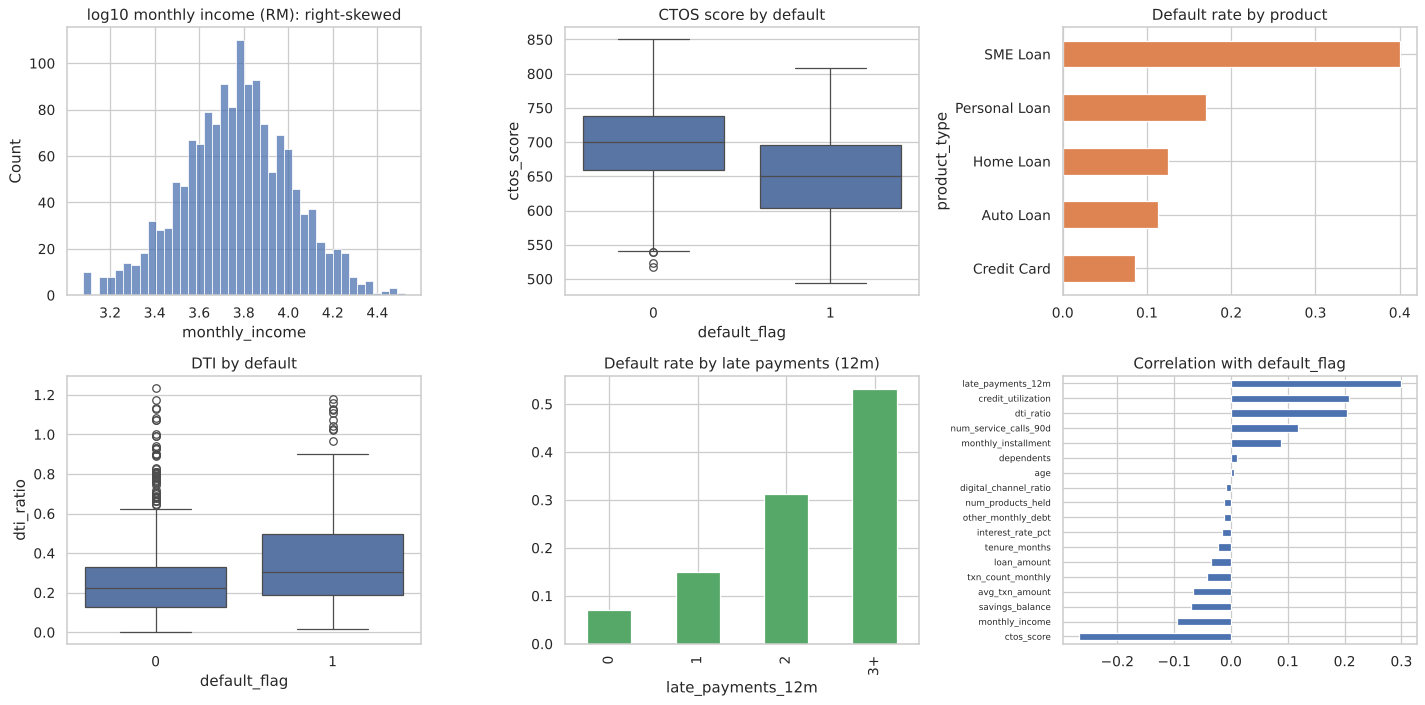

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(np.log10(raw["monthly_income"]), bins=40, ax=ax[0,0], color="#4c72b0"); ax[0,0].set_title("log10 monthly income (RM): right-skewed")
sns.boxplot(data=raw, x="default_flag", y="ctos_score", ax=ax[0,1]); ax[0,1].set_title("CTOS score by default")
raw.groupby("product_type")["default_flag"].mean().sort_values().plot.barh(ax=ax[0,2], color="#dd8452"); ax[0,2].set_title("Default rate by product")
sns.boxplot(data=raw, x="default_flag", y="dti_ratio", ax=ax[1,0]); ax[1,0].set_title("DTI by default")
raw.groupby(pd.cut(raw["late_payments_12m"], [-1,0,1,2,10], labels=["0","1","2","3+"]))["default_flag"].mean().plot.bar(ax=ax[1,1], color="#55a868"); ax[1,1].set_title("Default rate by late payments (12m)")
num = raw.select_dtypes("number").drop(columns=["loan_term_months"])
num.corr()["default_flag"].drop("default_flag").sort_values().plot.barh(ax=ax[1,2], color="#4c72b0"); ax[1,2].set_title("Correlation with default_flag"); ax[1,2].tick_params(axis="y", labelsize=7)
plt.tight_layout()

### 1.3 What the generated text looks like

In [6]:
sample = raw.dropna(subset=["customer_feedback"]).sample(8, random_state=7)[["customer_id", "default_flag", "customer_feedback"]]
print("Unique feedback texts:", raw["customer_feedback"].nunique(), "of", raw["customer_feedback"].notna().sum())
print("Feedback missing:", raw["customer_feedback"].isna().sum(), "| agent_note missing:", raw["agent_note"].isna().sum())
print("Avg words per feedback:", raw["customer_feedback"].dropna().str.split().str.len().mean().round(1))
sample

Unique feedback texts: 1384 of 1433
Feedback missing: 67 | agent_note missing: 318
Avg words per feedback: 24.0


,customer_id,default_flag,customer_feedback
249,CUST100249,0,Just wanted to say well done. The app is smooth and transfers are instant.
257,CUST100257,0,Honestly very disappointed. An overlimit charge of RM25 is unfair. I was charged twice for the same fee this month. If not I will consider closing my account.
815,CUST100815,0,Just a note from my side. The processing fee was not clearly explained when I signed up. I have never had any problem with my payments or the service.
74,CUST100074,0,Quite upset right now. I cannot log in to online banking for 2 days now.
681,CUST100681,1,"Not acceptable. I'm worried I will not be able to pay this month, can we reschedule? I expect a proper response boleh tolong?"
850,CUST100850,0,I am not happy with this at all. I had to use my credit card for daily needs and the balance is getting out of control. Got a suspicious SMS pretending to be from the bank and I am worried about my account. I don't know what else to do.
671,CUST100671,0,"Hello, Is there a lower interest rate if I refinance my credit card? I have never had any problem with my payments or the service. Appreciate a reply sangat lambat"
870,CUST100870,0,Quite upset right now. My salary was cut and I cannot keep up with the RM450 instalment.


In [7]:
raw.dropna(subset=["agent_note"]).sample(5, random_state=3)[["customer_id", "agent_note"]]

,customer_id,agent_note
605,CUST100605,"[Hotline] Cust contacted re interest rate complaint. Fee reversed as goodwill. Mild concern, monitor next cycle."
1422,CUST101422,"[WhatsApp] Cust contacted re product enquiry. Checked eligibility. Account healthy, upsell candidate."
1424,CUST101424,[Email] Cust contacted re app/login issue. Logged ticket with IT. Payment pattern slightly irregular.
704,CUST100704,"[WhatsApp] Cust contacted re inability to meet instalment. Advised to submit income proof. Mild concern, monitor next cycle."
1134,CUST101134,"[WhatsApp] Cust contacted re satisfaction check. Offered loyalty promo. Account healthy, upsell candidate."


## 2. LLM/SLM feature extraction

Two interchangeable back-ends produce **identical output columns**:

* `extract_with_hf` (`src/extract_features_hf.py`): real small language models (multilingual XLM-R sentiment + DistilBERT zero-shot classifier). Run it with internet access by setting `USE_HF = True`.
* `extract_offline` (`src/extract_features.py`): a lexicon/rule-based **SLM stand-in** used here because the build environment had no network. It handles negation, intensifiers and Malay words.

Features extracted from `customer_feedback` + `agent_note`:

| Feature | Meaning |
|---|---|
| `sentiment_score` / `sentiment_label` | polarity in [-1, 1] and Negative / Neutral / Positive |
| `text_topic` | complaint/intent category (6 classes) |
| `text_risk_score` / `text_risk_category` | credit-risk signal in the language (hardship cues, broken promises, income loss) → Low / Medium / High |

In [8]:
if USE_HF:
    from extract_features_hf import extract_with_hf
    enriched = extract_with_hf(raw)
else:
    enriched = extract_offline(raw)
enriched[["customer_feedback", "sentiment_score", "sentiment_label", "text_topic", "text_risk_score", "text_risk_category"]].dropna().sample(8, random_state=11)

,customer_feedback,sentiment_score,sentiment_label,text_topic,text_risk_score,text_risk_category
378,"Following up on my last contact. I'm worried I will not be able to pay this month, can we reschedule? Please advise.",-0.378,Negative,repayment_hardship,0.950,High
863,Writing in regarding my account. I would like to know the eligibility for a top-up loan.,0.000,Neutral,product_inquiry,0.832,High
912,I have raised this before and nothing changed. I had to use my credit card for daily needs and the balance is getting out of control. I missed the last paymnet by 29 days because my income came in late. Really hope someone takes this seriously.,-0.378,Negative,repayment_hardship,0.993,High
421,Quite upset right now. An overlimit charge of RM120 is unfair.,-0.651,Negative,fees_charges,0.899,High
632,Just wanted to say well done. The app is smooth and transfers are instant. Thanks again.,0.853,Positive,praise_loyalty,0.220,Low
705,"To whom it may concern, The annual fee was billed again after I asked to waive it. Appreciate a reply.",0.000,Neutral,fees_charges,0.401,Medium
1182,Very stressed about this. Payment in the app shows pending but the money was already deducted. I waited 35 minutes on the hotline before anyone answered. Please fix this soon.,-0.803,Negative,app_service_issue,0.911,High
112,"Just a note from my side. Interested in a fixed deposit, what are the current rates?",0.000,Neutral,product_inquiry,0.119,Low


### 2.1 Validating the extractors against the hidden ground truth
Because we simulated the text we know the *true* tone/topic/stress, which real projects never have. This lets us measure extractor quality.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
m = enriched.merge(truth, on="customer_id"); h = m[m["has_feedback"] == 1]
print("Sentiment accuracy:", round((h["sentiment_label"] == h["true_sentiment"]).mean(), 3))
print("Topic accuracy    :", round((h["text_topic"] == h["true_topic"]).mean(), 3))
print("Corr(text_risk_score, true text stress):", round(m["text_risk_score"].corr(m["true_text_stress"]), 3))
print()
print(pd.crosstab(h["true_sentiment"], h["sentiment_label"], rownames=["true"], colnames=["predicted"]))

Sentiment accuracy: 0.757
Topic accuracy    : 0.909
Corr(text_risk_score, true text stress): 0.667

predicted  Negative  Neutral  Positive
true                                  
Negative        499       18         9
Neutral         235      255        79
Positive          3        4       331


In [10]:
print(classification_report(h["true_topic"], h["text_topic"], digits=3))

                    precision    recall  f1-score   support

 app_service_issue      0.927     0.911     0.919       224
      fees_charges      0.811     0.960     0.879       223
    fraud_security      0.720     0.889     0.796        81
    praise_loyalty      0.997     0.870     0.929       354
   product_inquiry      0.959     0.861     0.908       274
repayment_hardship      0.912     0.968     0.939       277

          accuracy                          0.909      1433
         macro avg      0.888     0.910     0.895      1433
      weighted avg      0.918     0.909     0.910      1433


**Reading the results.** Negative and Positive are recognised well; *Neutral* is the weak class (polite complaints such as "Please advise on restructuring…" are read as negative). That is a known limitation of lexicon methods and is the main reason to switch to a real SLM (`USE_HF = True`) and compare.

## 3. Does the AI-extracted risk signal relate to default?

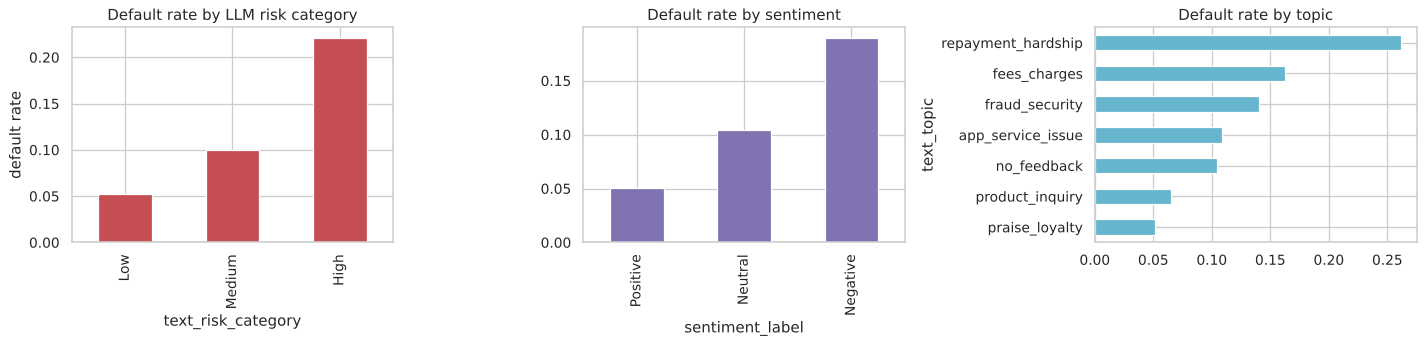

,customers,default_rate,feature
High,601,0.221,text_risk_category
Low,538,0.052,text_risk_category
Medium,361,0.100,text_risk_category
Negative,737,0.190,sentiment_label
Neutral,344,0.105,sentiment_label
Positive,419,0.050,sentiment_label


In [11]:
chk = pd.concat([
    enriched.groupby("text_risk_category")["default_flag"].agg(["size", "mean"]).rename(columns={"size": "customers", "mean": "default_rate"}).assign(feature="text_risk_category"),
    enriched.groupby("sentiment_label")["default_flag"].agg(["size", "mean"]).rename(columns={"size": "customers", "mean": "default_rate"}).assign(feature="sentiment_label"),
]).round(3)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
enriched.groupby("text_risk_category")["default_flag"].mean().reindex(["Low", "Medium", "High"]).plot.bar(ax=ax[0], color="#c44e52"); ax[0].set_title("Default rate by LLM risk category"); ax[0].set_ylabel("default rate")
enriched.groupby("sentiment_label")["default_flag"].mean().reindex(["Positive", "Neutral", "Negative"]).plot.bar(ax=ax[1], color="#8172b2"); ax[1].set_title("Default rate by sentiment")
enriched.groupby("text_topic")["default_flag"].mean().sort_values().plot.barh(ax=ax[2], color="#64b5cd"); ax[2].set_title("Default rate by topic")
plt.tight_layout()
chk

## 4. Customer segmentation

K-Means on standardised behavioural + financial features (including the extracted sentiment). Silhouette scores are low and flat across k (typical for overlapping behavioural data), so **k = 5** is chosen for business interpretability. Clusters are named from their centroid profiles by one-to-one assignment to business archetypes.

In [12]:
seg, sil, k, prof = segment_customers(enriched, k=5)
print("Silhouette by k:", {kk: round(v, 3) for kk, v in sil.items()})
summary = seg.groupby("customer_segment").agg(customers=("customer_id", "size"), income=("monthly_income", "mean"), savings=("savings_balance", "mean"),
    digital=("digital_channel_ratio", "mean"), tenure=("tenure_months", "mean"), utilisation=("credit_utilization", "mean"), dti=("dti_ratio", "mean"),
    sentiment=("sentiment_score", "mean"), default_rate=("default_flag", "mean")).round(2)
summary

Silhouette by k: {3: 0.096, 4: 0.102, 5: 0.107, 6: 0.105, 7: 0.102}


,customers,income,savings,digital,tenure,utilisation,dti,sentiment,default_rate
customer_segment,,,,,,,,,
Affluent Active,407,8443.39,40373.14,0.81,48.41,0.37,0.23,0.05,0.07
Entry-Level Everyday,412,3851.72,7972.17,0.70,54.25,0.41,0.23,-0.29,0.21
Loyal Multi-Product,193,8340.16,43717.39,0.62,142.62,0.39,0.24,-0.17,0.10
Stretched Borrowers,115,6560.78,25212.01,0.70,53.59,0.39,0.75,-0.43,0.32
Traditional Branch Users,373,7760.51,44087.00,0.50,49.47,0.35,0.22,0.09,0.07


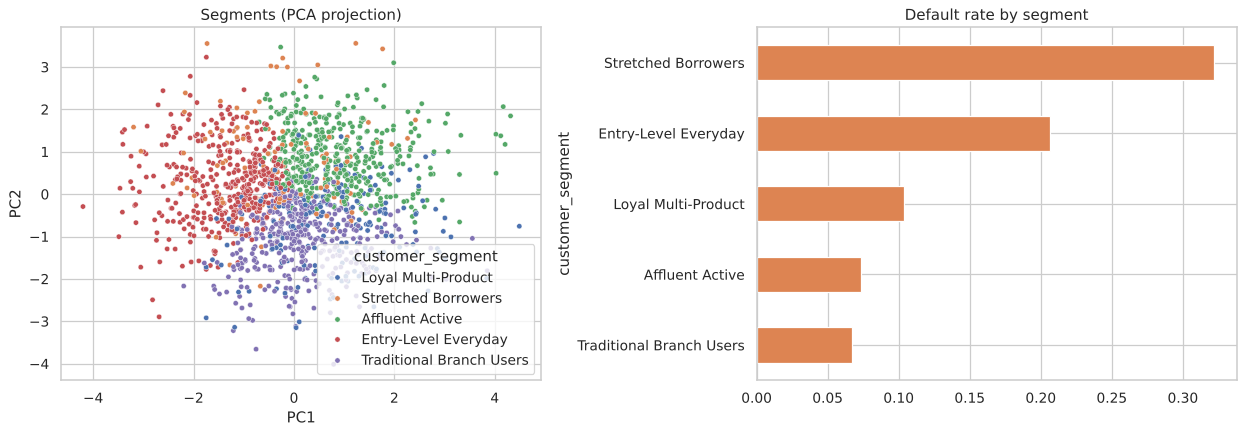

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
X = seg[SEG_FEATURES].fillna(seg[SEG_FEATURES].median()).copy(); X["monthly_income"] = np.log1p(X["monthly_income"]); X["savings_balance"] = np.log1p(X["savings_balance"])
P = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=P[:,0], y=P[:,1], hue=seg["customer_segment"], s=18, ax=ax[0]); ax[0].set_title("Segments (PCA projection)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
seg.groupby("customer_segment")["default_flag"].mean().sort_values().plot.barh(ax=ax[1], color="#dd8452"); ax[1].set_title("Default rate by segment")
plt.tight_layout()

## 5. Sanity check: do the new features improve prediction?
Not the formal modelling task (that is Component 2), only a quick 5-fold × 4-repeat cross-validated check with two simple learners, comparing **numeric-only** vs **numeric + AI-extracted features**. The AI features are derived from text only, never from `default_flag`, so there is no leakage.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

y = seg["default_flag"]
cat_base = ["gender", "marital_status", "education", "employment_status", "region", "product_type"]
num_base = [c for c in seg.select_dtypes("number").columns if c not in ["default_flag", "segment_id", "sentiment_score", "text_risk_score", "has_feedback", "has_agent_note"]]
ai_num, ai_cat = ["sentiment_score", "text_risk_score", "has_feedback", "has_agent_note"], ["text_topic", "text_risk_category", "customer_segment"]

def pipe(num, cat, model):
    pre = ColumnTransformer([("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
                             ("c", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("p", pre), ("m", model)])

from sklearn.model_selection import RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=42)
rows = []
for name, model in [("Decision Tree (depth 4)", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)),
                    ("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced"))]:
    for label, num, cat in [("Numeric only", num_base, cat_base), ("AI features only", ai_num, ["text_topic", "text_risk_category"]), ("Numeric + AI features", num_base + ai_num, cat_base + ai_cat)]:
        s = cross_val_score(pipe(num, cat, model), seg, y, cv=cv, scoring="roc_auc")
        rows.append({"model": name, "feature set": label, "ROC-AUC (mean)": round(s.mean(), 3), "std": round(s.std(), 3)})
pd.DataFrame(rows)

,model,feature set,ROC-AUC (mean),std
0,Decision Tree (depth 4),Numeric only,0.698,0.046
1,Decision Tree (depth 4),AI features only,0.660,0.038
2,Decision Tree (depth 4),Numeric + AI features,0.699,0.043
3,Logistic Regression,Numeric only,0.781,0.029
4,Logistic Regression,AI features only,0.694,0.042
5,Logistic Regression,Numeric + AI features,0.785,0.035


**Interpretation.** The AI-extracted text features carry real signal on their own (AUC clearly above 0.5, and default rates rise steadily from Low to High risk in §3), but on top of the numeric columns they add only a **marginal** gain, within one standard deviation across folds. Two honest reasons: (1) much of the hardship language in the text mirrors information already in DTI, utilisation and late payments; (2) the lexicon extractor is noisy, especially on Neutral sentiment. Re-running with real SLMs (`USE_HF = True`) is the obvious next experiment, and the group should report this finding as-is rather than tuning the simulation to inflate it.

## 6. Save the final feature-engineered dataset

In [15]:
final = seg.drop(columns=["segment_id"])
final.to_csv("data/bank_customers_enriched.csv", index=False)
print("Saved:", final.shape, "->", "data/bank_customers_enriched.csv")
print("Class balance:", final["default_flag"].value_counts().to_dict())
final.iloc[:3, -12:]

Saved: (1500, 37) -> data/bank_customers_enriched.csv
Class balance: {0: 1303, 1: 197}


,num_service_calls_90d,customer_feedback,agent_note,default_flag,sentiment_score,sentiment_label,text_topic,text_risk_score,text_risk_category,has_feedback,has_agent_note,customer_segment
0,0,"Sharing some feedback. Interested in a fixed deposit, what are the current rates? Do you have any promotion for balance transfer? Please advise.",NaN,0,0.000,Neutral,product_inquiry,0.401,Medium,1,0,Loyal Multi-Product
1,2,Following up on my last contact. I had to use my credit card for daily needs and the balance is getting out of control. Appreciate a reply terima kasih,"[WhatsApp] Cust contacted re request for payment relief. Arranged revised payment plan. Cust reports income loss, watchlist suggested.",0,0.632,Positive,repayment_hardship,0.983,High,1,1,Stretched Borrowers
2,1,"Hi team, I am already 12 days overdue and need help with a lower payment plan. What documents do I need to increase my credit limit? Please advise.",NaN,1,-0.378,Negative,repayment_hardship,0.874,High,1,0,Affluent Active


## 7. Summary, limitations and AI-usage disclosure

**Result.** 1,500 synthetic customers, 29 raw columns (19 numeric, 6 categorical, 2 free-text, 1 ID, 1 target) plus 8 AI-extracted features, ready for the modelling component with `default_flag` as target.

**Limitations (be explicit in the report)**
* All data is synthetic. Relationships were *designed* (e.g. higher DTI → higher default) so model results show the pipeline works, not real-world credit behaviour.
* The text is grammar-composed from GenAI-authored phrase pools, so it is less diverse than real customer language. A stronger variant generates each message with an LLM from the customer profile (prompt template provided in `src/extract_features_hf.py`).
* The submitted enriched CSV uses the **offline SLM stand-in**. Re-run with `USE_HF = True` and compare against it (a good extra analysis for the report).
* Extractor accuracy numbers (§2.1) are inflated relative to real data because we wrote both the phrases and the keyword lists; the hidden-label validation is still useful for relative comparison.
* Segmentation silhouette is low; the clusters are interpretable profiles, not sharply separated groups.

**AI-usage disclosure (draft, edit for your group)**
* Claude (Anthropic) was used to design the simulation, author the phrase pools and extraction rules, and write the code in `src/`.
* Group members must review the outputs, verify the code, and record their own prompts/contributions in the final report and GitHub history.